# Quantum Metal A.4 — full chip: six qubits, a tunable coupler and a multiplexed north feedline (Quantcore PDK rebuild)

**What the chip is.** The full-chip example of Qiskit Metal,
`docs/circuit-examples/full-design-flow-examples/A.4-Full-chip-design.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A4_full_chip.md`), which
the tutorial calls a teaching layout whose "resonator lengths are only roughly chosen". `Q_Main`, a
`TransmonPocket6` with six connection pads, is the hub: five λ/2 buses (6.0–7.6 mm) go to `Q1`, `Q2`
(`TransmonCrossFL` with flux lines, joined by the `TunableCoupler01` `Tune_C_Q12`) and to `Q3`, `Q4`, `Q5`
(`TransmonPocket6`, chained by two more buses). `Q_Main` is read out through a `CapNInterdigital` series capacitor,
`Q1`, `Q2` and the coupler through `LaunchpadWirebondCoupled` pads (λ/2 each); `Q3`–`Q5` are multiplexed on a north
feedline through a `CoupledLineTee` (λ/4) and two `CapNInterdigitalTee`s (λ/2). Three 5/3 µm flux lines (Q1, Q2,
coupler) and nine launchpads. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 11 × 8 mm centred on (0, −0.5 mm) | the source's chip grown by 0.6 mm on every side (box `(-600, -600, 11600, 8600)`, so the corner launchpads and the north feedline clear the frame's marker areas), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 9 `LaunchpadWirebond(Coupled)`s 840–850 µm in from the die edge | the same pads, moved to **100 µm** (`frame.pad_edge`) from the south / west / east edges (PDK pad rule) |
| junctions | Metal junction lines, `hfss_inductance` 14 nH (pockets) / 10 nH (crosses, coupler) | Quantcore Nb/AlOx/Nb trilayer junctions: `Q_Main` sized for the tutorial's f_q 4.96 GHz (R_n ≈ 98 kΩ, flagged); `Q3`–`Q5` PDK nominal; `Q1`, `Q2`, the coupler a PDK SQUID |
| cheese | **yes**: the notebook exports GDS with Metal's default cheese (25 µm squares every 100 µm), `no_cheese.buffer` 50 µm | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule(buffer=50)`) |
| routes | `RouteMeander` buses and readouts, `RoutePathfinder` flux lines | qcc meanders and `cpw` routes on the same pins with the same total lengths, fillet 99 µm |
| placement | as drawn | centred in x; in y pinned by the edge pads (Design 8) |

**Kept exactly:** every component with the tutorial's options, positions and orientations — the `TransmonPocket6`
connection pads (`loc_W` / `loc_H`, pad width and gap), the `TransmonCrossFL` claws (`connector_location`,
`claw_length` 95 µm), `TunableCoupler01` (`c_width` 500 µm, rotated 90°), the tees (`coupling_length` 200 µm
shorted; finger counts 8 / 11, finger lengths 0 / 50 µm), the launchpads (5/3 µm traces on the flux pads); every
route's end pins and total length (buses 6000 … 7600 µm, readouts 5000 … 6800 µm), the 99 µm fillet, and the three
flux-line paths (Metal's `RoutePathfinder` results: 4582, 3306 and 3954 µm before the pads moved).

**Simplified:** the qcc router puts each meander on one straight segment of a path given by waypoints (Metal's
`RouteMeander` meanders along the whole route with its `lead` / `asymmetry` / jog options), so the meander
footprints differ from the tutorial's picture; the waypoints keep all routes apart. The Q2 flux line's corners are
moved by up to 85 µm (Metal's 175 µm lead is too short for two 99 µm fillets in the qcc router).

**Assumed coupling:** the coupler island's ends face the cross arms of `Q1` and `Q2`; no route carries this, so it
is declared with `d.couple`, C ≈ 6 fF each from a coplanar-strip estimate (90 µm facing length, 37 µm gap). The
Q3D C-matrix of the `Q1_TC_Q2` group replaces it.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the nine launchpads, the readout line (the north feedline with its three tees,
and `Q_Main`'s series capacitor), the six qubits, their readout resonators, the coupling (the tunable coupler, its
readout and the seven buses), the three flux lines, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a4_full_chip.v1.ipynb`; both save the same
`a4_full_chip.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.lom import estimates as est

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the grown 12.2 × 9.2 mm box gets the QCT frame; the nine launchpads go 100 µm from their edges; every qubit and the coupler get a trilayer junction or SQUID; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so the feedline (pad → tee → tee → tee → pad) is drawn as
soon as the pads and the tees exist (segment 3), each readout once its qubit is there (segment 5), the buses and the
coupler's readout with the coupler (segment 6). The source builds them in one interleaved list; none of their
positions depends on that order (fixed Metal coordinates and waypoints).

| segment | what is placed here |
|---|---|
| 1 | the grown 12.2 × 9.2 mm box with the QCT frame and the original's Metal cheese rule |
| 2 | the nine launchpads (south, west, east), three of them with the 5/3 µm flux-line trace |
| 3 | the readout line: the north feedline through three tees, and `Q_Main`'s series capacitor to its pad |
| 4 | the six qubits: `Q_Main`, the two crossmons `Q1` / `Q2`, `Q3`–`Q5`, with trilayer junctions / SQUIDs |
| 5 | the six readout resonators: to the series capacitor, to two coupled launchpads, to the three tees |
| 6 | the coupling: the tunable coupler with its readout and declared couplings, and the seven λ/2 buses |
| 7 | the control routing: the three 5/3 µm flux lines |
| 8 | the whole chip: `Q_Main`'s target, sim groups, centring in x, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional). Metal centres this chip on (0, −0.5 mm), so
every Metal position is shifted by `(X0, Y0)` (`P(x, y)` does it); the box is the source's 11 × 8 mm grown by
0.6 mm per side so the corner launchpads clear the 500 µm marker areas.

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (Fab 1), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule(buffer=50)}` hands the build Metal's rule (25 µm squares every 100 µm, 50 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

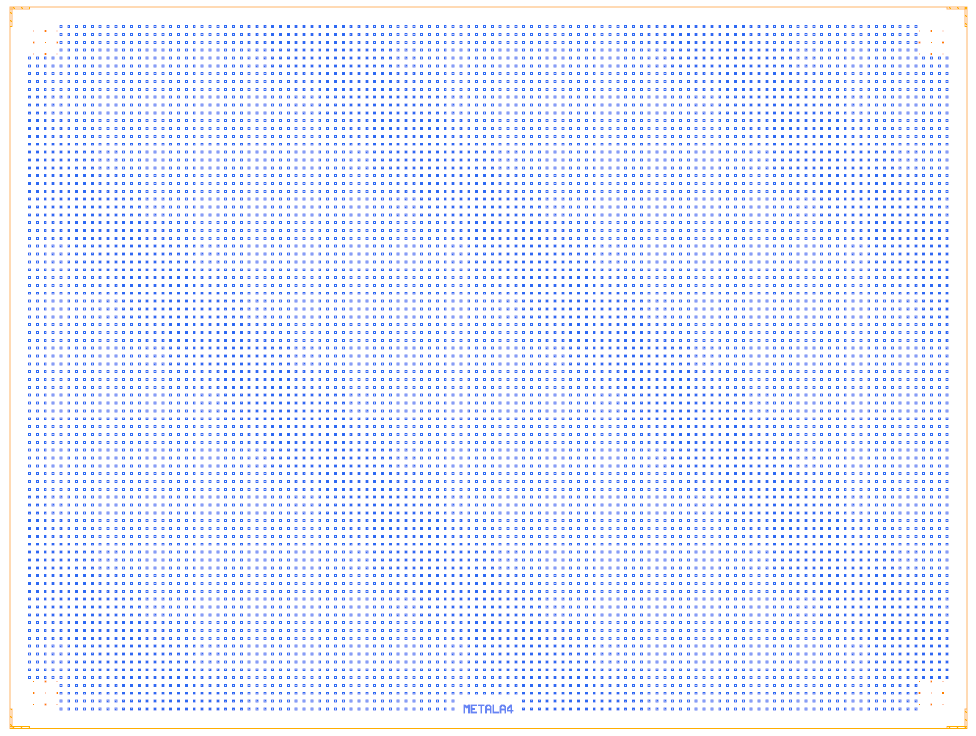

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a4_full_chip_s1_die.png')

In [5]:
d = Designer("a4_full_chip", box=(-600, -600, 11600, 8600), chip={"name_chip": "MetalA4", "cheese": metal_cheese_rule(buffer=50)},
             live=LIVE)
X0, Y0 = 5500, 4500                              # Metal's 11 × 8 mm chip is centred on (0, −0.5 mm)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
layout_step(d, OUT / "a4_full_chip_s1_die.png", size=(976, 736), width=450)

## Design 2 · Bond pads: the PDK pad rule

The tutorial's nine launchpads sit 840–850 µm in from the edges of this die: four on the south edge (the Q_Main
readout, the Q1 flux line and readout, the coupler flux line), four on the west edge (the coupler and Q2 readouts,
the Q2 flux line, the north feedline input) and the feedline output on the east edge. In the Quantcore PDK the outer
edge of every bond pad's etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did:
`edge="s"` / `"w"` / `"e"` slides each pad perpendicular to its edge until it is there; its position along the
edge is kept, so every line still arrives on the pad's axis and only gets longer. The three flux-line pads keep the
5/3 µm trace of the flux lines; the readout pads of Q1, Q2 and the coupler are the capacitively coupled
`LaunchpadWirebondCoupled`.

The table measures the pad rule on the built layout; the picture zooms on `Q1`'s flux-line pad at the south edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| Launch_QMain_Read | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q1_FL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_Q1_Read | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| Launch_TuneC_FL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| Launch_TuneC_Read | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| Launch_Q2_Read | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| Launch_Q2_FL | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_NW | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| Launch_NE | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

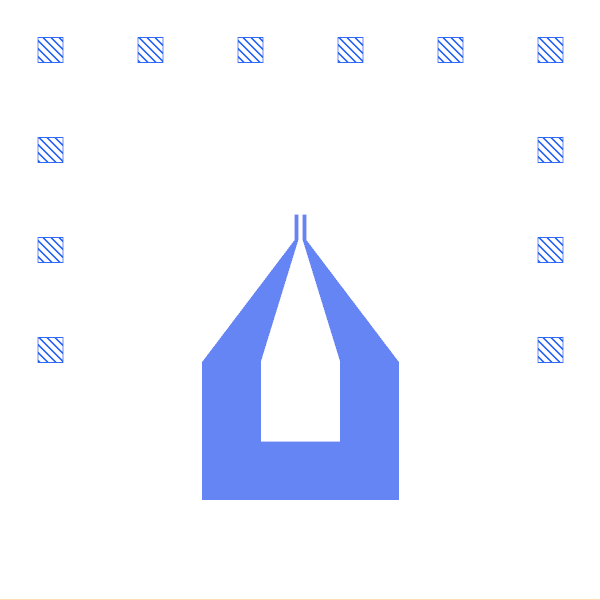

**On the chip so far:** 9 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 9 component(s) `Launch_QMain_Read`, `Launch_Q1_FL`, `Launch_Q1_Read`, `Launch_TuneC_FL`, `Launch_TuneC_Read`, `Launch_Q2_Read`, `Launch_Q2_FL`, `Launch_NW` … (+1).

WindowsPath('examples/designs/metal/a4_full_chip_s2_pads.png')

In [6]:
lp = lambda n, x, y, r, edge, cell="metal:LaunchpadWirebond", **kw: d.add(n, cell, at=P(x, y), rot=r, edge=edge, **kw)
with d.batch():
    l_qm = lp("Launch_QMain_Read", 2000, -4000, 90, "s")
    l_q1fl = lp("Launch_Q1_FL", 0, -4000, 90, "s", trace_width=5, trace_gap=3)
    l_q1r = lp("Launch_Q1_Read", -2000, -4000, 90, "s", "metal:LaunchpadWirebondCoupled")
    l_tcfl = lp("Launch_TuneC_FL", -4000, -4000, 90, "s", trace_width=5, trace_gap=3)
    l_tcr = lp("Launch_TuneC_Read", -5000, -3000, 0, "w", "metal:LaunchpadWirebondCoupled")
    l_q2r = lp("Launch_Q2_Read", -5000, -1000, 0, "w", "metal:LaunchpadWirebondCoupled")
    l_q2fl = lp("Launch_Q2_FL", -5000, 1000, 0, "w", trace_width=5, trace_gap=3)
    l_nw = lp("Launch_NW", -5000, 3000, 0, "w")
    l_ne = lp("Launch_NE", 5000, 3000, 180, "e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "Launch_Q1_FL.tie")
layout_step(d, OUT / "a4_full_chip_s2_pads.png", box=(px - 300, -600, px + 300, 0), size=(600, 600), width=300)

## Design 3 · Readout: the north feedline and `Q_Main`'s series capacitor

The readout line needs no qubit, so it comes first. Three tees sit on the north feedline at y = +3 mm (Metal frame),
above `Q3`, `Q4` and `Q5`: `Q3_Read_T` a `CoupledLineTee` (200 µm coupled arm, shorted, so `Q3`'s readout will be a
λ/4), `Q4_Read_T` and `Q5_Read_T` `CapNInterdigitalTee`s (8 fingers of length 0, a gap capacitor; 11 fingers of
50 µm). The feedline is four straight `cpw` sections `Launch_NW` → the three tees → `Launch_NE`. `Q_Main` is read out
alone, through the series `CapNInterdigital` `Read_Q_Main_Cap` 0.5 mm above its south pad (`Read_Q_Main_Cap_Launch`,
a short straight).

Q4_Read_T ports: ['prime_end', 'prime_start', 'second_end'] | Read_Q_Main_Cap ports: ['north_end', 'south_end']


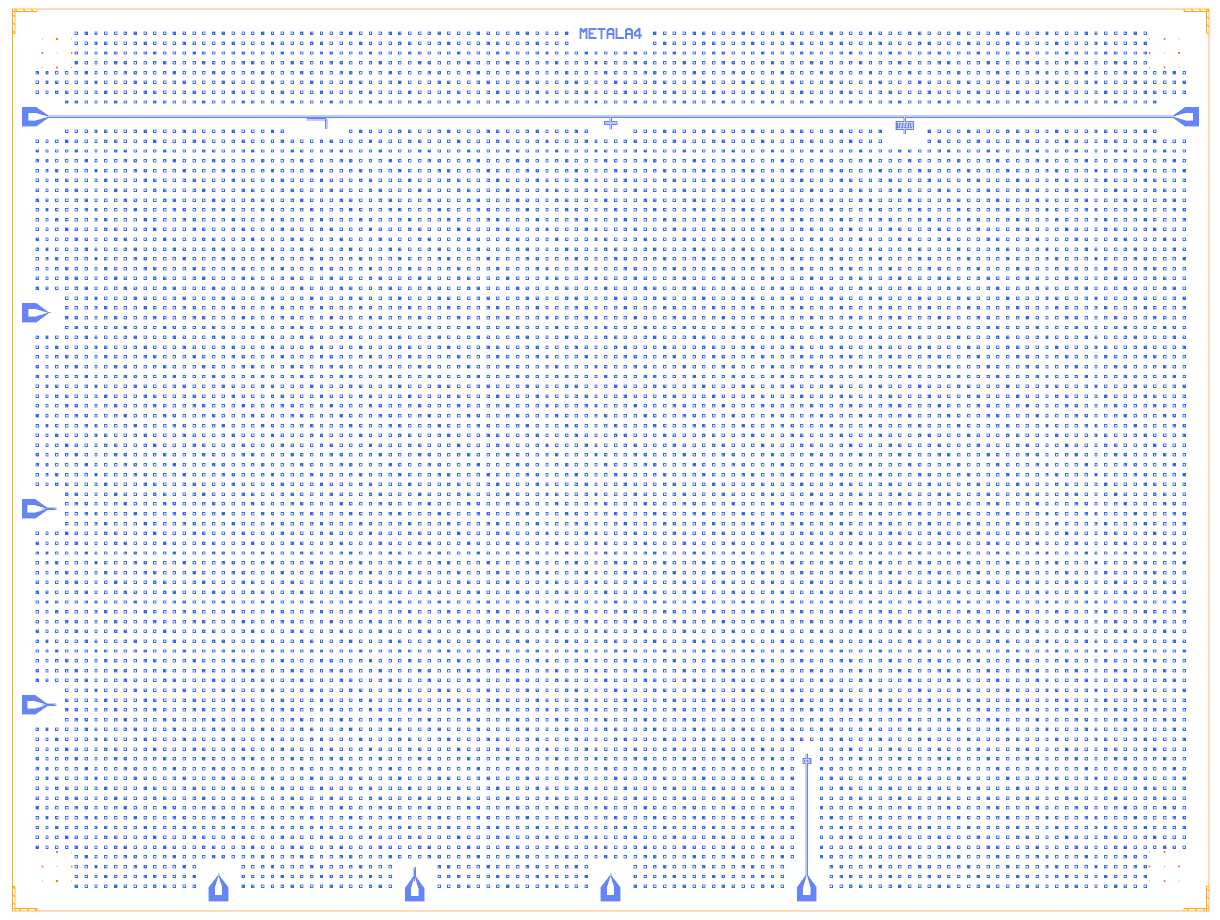

**On the chip so far:** 9 pads · 0 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 4 component(s) `Read_Q_Main_Cap`, `Q3_Read_T`, `Q4_Read_T`, `Q5_Read_T` and 5 route(s) `ML_TL_01`, `ML_TL_02`, `ML_TL_03`, `ML_TL_04`, `Read_Q_Main_Cap_Launch`.

WindowsPath('examples/designs/metal/a4_full_chip_s3_readout_line.png')

In [7]:
R = 99                                           # Metal fillet
with d.batch():
    cap = d.add("Read_Q_Main_Cap", "metal:CapNInterdigital", at=P(2000, -3500))
    t3 = d.add("Q3_Read_T", "metal:CoupledLineTee", at=P(-3000, 3000), coupling_length=200, open_termination=False)
    t4 = d.add("Q4_Read_T", "metal:CapNInterdigitalTee", at=P(0, 3000), finger_length=0, finger_count=8)
    t5 = d.add("Q5_Read_T", "metal:CapNInterdigitalTee", at=P(3000, 3000), finger_length=50, finger_count=11)
    # north multiplexed feedline through the three tees
    d.route("ML_TL_01", l_nw.tie, t3.prime_start)
    d.route("ML_TL_02", t3.prime_end, t4.prime_start)
    d.route("ML_TL_03", t4.prime_end, t5.prime_start)
    d.route("ML_TL_04", t5.prime_end, l_ne.tie)
    d.route("Read_Q_Main_Cap_Launch", cap.south_end, l_qm.tie)
print("Q4_Read_T ports:", sorted(t4.ports), "| Read_Q_Main_Cap ports:", sorted(cap.ports))
layout_step(d, OUT / "a4_full_chip_s3_readout_line.png", size=(1220, 920), width=480)

## Design 4 · Qubit placement: the six qubits and their junctions

**Junctions first.** Every qubit gets a Quantcore Nb/AlOx/Nb trilayer junction on the PDK junction rule (Nb Δ 1.4 meV,
I_c·R_n = πΔ/2e, R_n·A 13.5 kΩ·µm² and C_J 50 fF/µm² assumed); `trilayer_junction` returns the instance parameters
and the drawn junction's L_J / C_J (for the LOM and the FEM junction port):
- `Q3`–`Q5`: the PDK nominal junction (0.5 × 0.6 µm fingers, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF);
- `Q1`, `Q2` and the coupler (flux lines): a PDK SQUID of two 0.25 × 0.6 µm junctions (45 kΩ in parallel, L_J
  6.73 nH at zero flux);
- `Q_Main`: the only qubit with a stated target (f_q 4.96 GHz, Metal's Q3D + LOM result): `size_junction` solves the
  junction for it on the pocket's C_Σ (54.9 fF from this design's LOM before the rebuild). The small pocket needs
  L_J ≈ 14.6 nH: a 0.23 µm finger, **R_n ≈ 98 kΩ, outside the 40–50 kΩ window**. That is flagged (DRC `pdk_rn`),
  not retuned: the value is the source's.

**The qubits** keep the tutorial's options and positions: the six-pad `TransmonPocket6`s `Q_Main`, `Q3`, `Q4`, `Q5`
(`pads6` packs `loc_W`, `loc_H`, pad width and gap per connection pad) and the two `TransmonCrossFL`s `Q1` / `Q2`
with their claws and flux T-lines. The tunable coupler between `Q1` and `Q2` comes with the coupling (Design 6). The
second picture zooms on `Q1` / `Q2`, where the coupler will sit.

Q_Main: L_J 14.64 nH, C_J 6.9 fF, R_n 99 kΩ, fingers 0.23 × 0.6 µm; R_n 98.6 kΩ is outside the process window 40–50 kΩ (f_q 4.96 GHz with C_Σ 61.7 fF needs E_J/h 11.1 GHz)
Q3–Q5: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} | Q1, Q2, coupler: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q_Main ports: ['bus_01', 'bus_02', 'bus_03', 'bus_04', 'bus_05', 'readout', 'squid_a', 'squid_b']
Q1 ports: ['bus_01', 'flux_line', 'readout', 'squid_a', 'squid_b']


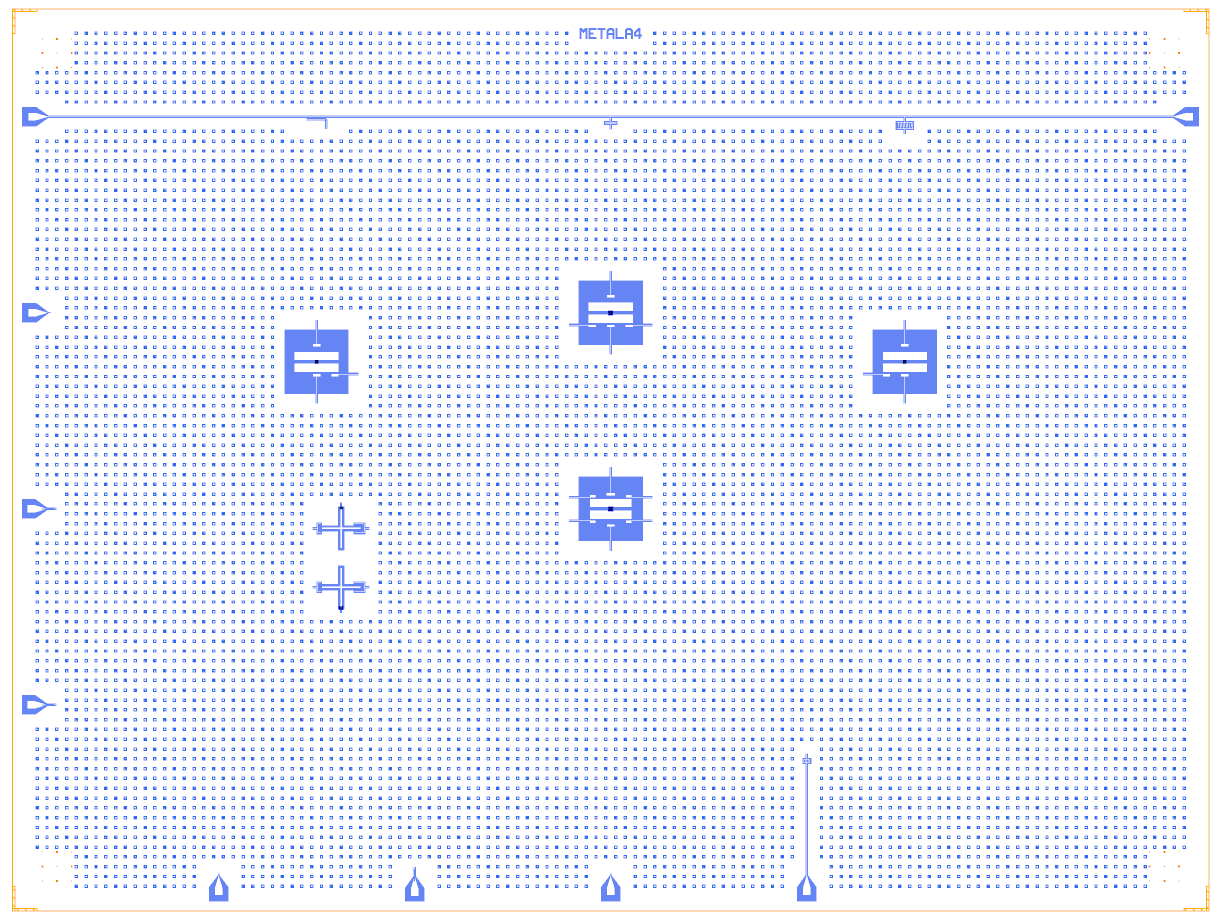

**On the chip so far:** 9 pads · 6 qubits · 4 other components · 5 routes · 0 declared couplings. **This step added** 6 component(s) `Q_Main`, `Q1`, `Q2`, `Q3`, `Q4`, `Q5`.

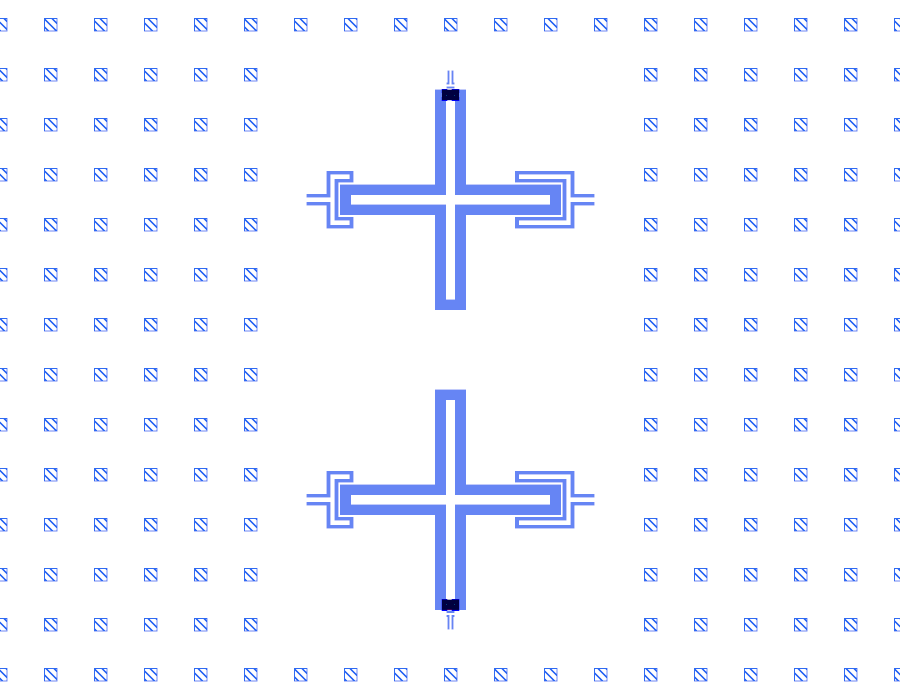

WindowsPath('examples/designs/metal/a4_full_chip_step_parts.png')

In [8]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket6")
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
SIZED_QM = size_junction(4.96, 54.9, c_includes_junction=False)    # C_Σ 54.9 fF without the junction (pre-rebuild LOM)
QM_PARAMS, JJ_QM = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZED_QM.lj_nH)
print(f"Q_Main: L_J {JJ_QM['Lj_nH']} nH, C_J {JJ_QM['Cj_fF']} fF, R_n {SIZED_QM.rn_kohm:.0f} kΩ, fingers "
      f"{SIZED_QM.finger_width} × {SIZED_QM.second_finger_width} µm; " + "; ".join(SIZED_QM.notes))
print("Q3–Q5:", JJ_PARAMS, JUNCTION, "| Q1, Q2, coupler:", SQ_PARAMS, SQUID)
pads6 = lambda **kw: {k: dict(zip(("loc_W", "loc_H", "pad_width", "pad_gap"), v)) for k, v in kw.items()}
with d.batch():
    qm = d.add("Q_Main", "metal:TransmonPocket6", at=P(0, -1000), pad_width=425, pocket_height=650, junction=JJ_QM,
               **QM_PARAMS, connection_pads=pads6(readout=(0, -1, 80, 50), bus_01=(-1, -1, 60, 10),
                                                 bus_02=(-1, 1, 60, 10), bus_03=(0, 1, 90, 30),
                                                 bus_04=(1, 1, 60, 10), bus_05=(1, -1, 60, 10)))
    q1 = d.add("Q1", "metal:TransmonCrossFL", at=P(-2750, -1800), junction=SQUID, **SQ_PARAMS, fl_options={},
               connection_pads={"bus_01": {"connector_location": "180", "claw_length": 95},
                                "readout": {"connector_location": "0"}})
    q2 = d.add("Q2", "metal:TransmonCrossFL", at=P(-2750, -1200), rot=180, junction=SQUID, **SQ_PARAMS, fl_options={},
               connection_pads={"bus_02": {"connector_location": "0", "claw_length": 95},
                                "readout": {"connector_location": "180"}})
    q3 = d.add("Q3", "metal:TransmonPocket6", at=P(-3000, 500), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_03=(0, -1, 80, 15), bus_q3_q4=(1, -1, 80, 15), readout=(0, 1, 80, 50)))
    q4 = d.add("Q4", "metal:TransmonPocket6", at=P(0, 1000), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_04=(0, -1, 80, 15), bus_q3_q4=(-1, -1, 80, 15), bus_q4_q5=(1, -1, 80, 15),
                                     readout=(0, 1, 80, 50)))
    q5 = d.add("Q5", "metal:TransmonPocket6", at=P(3000, 500), junction=JUNCTION, **JJ_PARAMS,
               connection_pads=pads6(bus_05=(0, -1, 80, 15), bus_q4_q5=(-1, -1, 80, 15), readout=(0, 1, 80, 50)))
print("Q_Main ports:", sorted(qm.ports))
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "a4_full_chip_s4_qubits.png", size=(1220, 920), width=480)
cx, cy = P(-2750, -1500)
snap(d, OUT / "a4_full_chip_step_parts.png", box=(cx - 900, cy - 700, cx + 900, cy + 700), size=(900, 700), width=400)

## Design 5 · Readout: the six readout resonators

Fixed-length λ/2 readouts (and one λ/4) from each qubit's `readout` pad or claw: `Read_Q_Main` (5600 µm) to the
series capacitor's north pin, `Read_Q1` (6800 µm) and `Read_Q2` (5400 µm) to their `LaunchpadWirebondCoupled`s,
`Read_Q3` (5000 µm, a λ/4 on the shorted coupled-line tee), `Read_Q4` (5800 µm) and `Read_Q5` (5400 µm) to their
interdigital tees. The waypoints give each meander its own straight; `Read_Q4` / `Read_Q5` have none (an automatic
Manhattan path up to their tee). The waypoint paths are shorter than the lengths, so the router draws one KQC
`Meander` for each leftover on the longest free straight, with no more turns than keep each turn at least the 99 µm
bend radius wide.

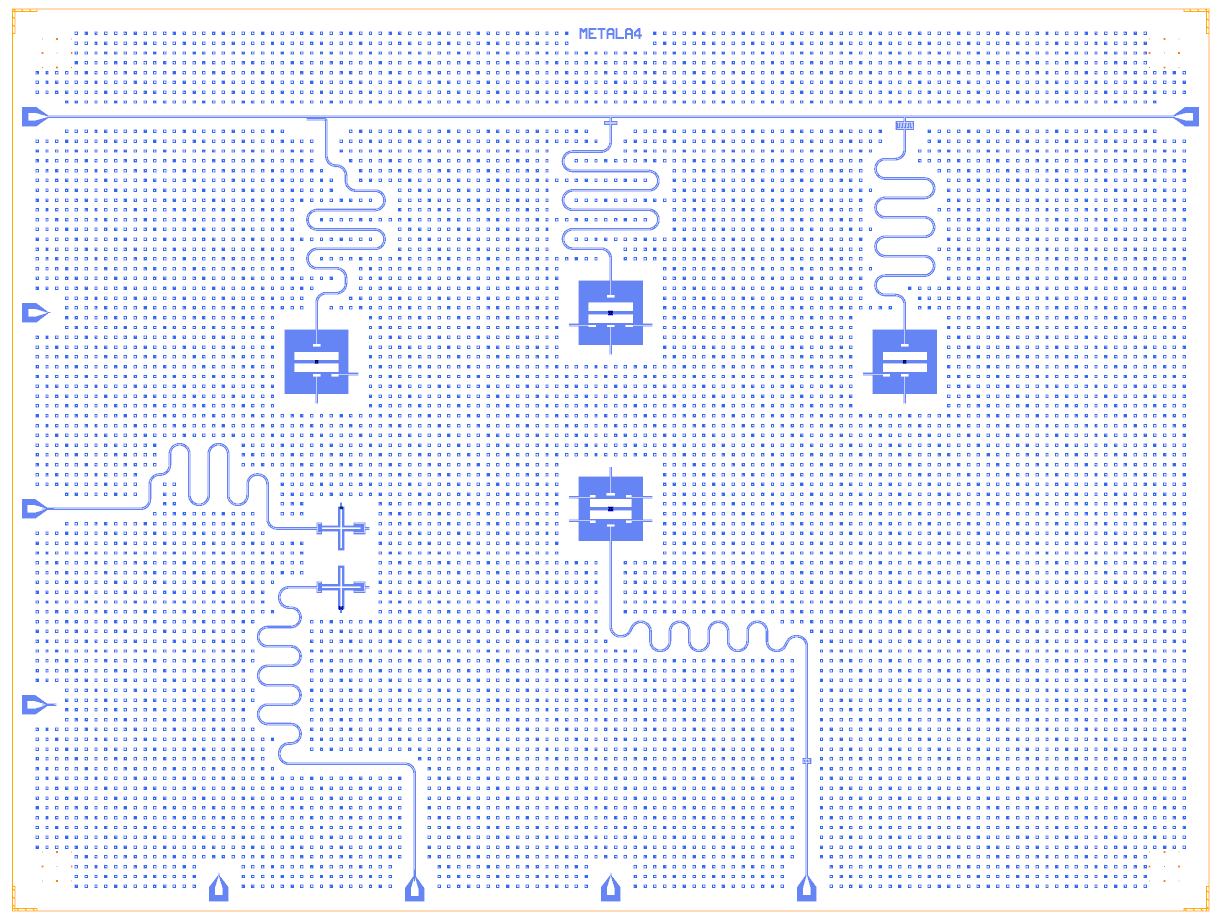

**On the chip so far:** 9 pads · 6 qubits · 4 other components · 11 routes · 0 declared couplings. **This step added** 6 route(s) `Read_Q_Main`, `Read_Q1`, `Read_Q2`, `Read_Q3`, `Read_Q4`, `Read_Q5`.

WindowsPath('examples/designs/metal/a4_full_chip_s5_readouts.png')

In [9]:
with d.batch():
    # individual readouts (λ/2: claw / pad → coupled launchpad or series capacitor)
    d.route("Read_Q_Main", qm.readout, cap.north_end, meander=5600, r=R, nodes=[(5500, 2200), (7500, 2200)])
    d.route("Read_Q1", q1.readout, l_q1r.tie, meander=6800, r=R, nodes=[(2120, 2700), (2120, 900), (3500, 900)])
    d.route("Read_Q2", q2.readout, l_q2r.tie, meander=5400, r=R,
            nodes=[(2000, 3300), (2000, 3850), (800, 3850), (800, 3500)])
    # the three readouts on the north feedline
    d.route("Read_Q3", q3.readout, t3.second_end, meander=5000, r=R,
            nodes=[(2500, 5700), (2800, 5700), (2800, 7000), (2600, 7000)])
    d.route("Read_Q4", q4.readout, t4.second_end, meander=5800, r=R)
    d.route("Read_Q5", q5.readout, t5.second_end, meander=5400, r=R)
layout_step(d, OUT / "a4_full_chip_s5_readouts.png", size=(1220, 920), width=480)

## Design 6 · Coupling: the tunable coupler and the seven buses

**The tunable coupler** `Tune_C_Q12` (`TunableCoupler01`, `c_width` 500 µm, rotated 90°) sits between the two
crossmons with a PDK SQUID (Design 4), its `Control` claw read out through `Read_TuneC` (5800 µm λ/2) to its coupled
launchpad. Its island ends face the cross arms of `Q1` and `Q2`; no route carries that, so the two capacitances are
declared with `d.couple`, C ≈ 6 fF each from a coplanar-strip estimate (90 µm facing length, 37 µm gap). The Q3D job
`Q1_TC_Q2` replaces them.

**The buses:** seven fixed-length λ/2 meanders between two pads: `Q_Main` to each of `Q1`–`Q5` (6000 … 7600 µm) and
`Q3`–`Q4`, `Q4`–`Q5` (6400, 6800 µm). The waypoints give each meander its own straight to fold on (`Bus_04` on its third
segment, `.set(meander_segment=3)`), so all lines stay apart.

coupler ports: ['Control', 'Flux', 'squid_a', 'squid_b'] | C(TC ↔ Q1/Q2) estimate: 5.86 fF


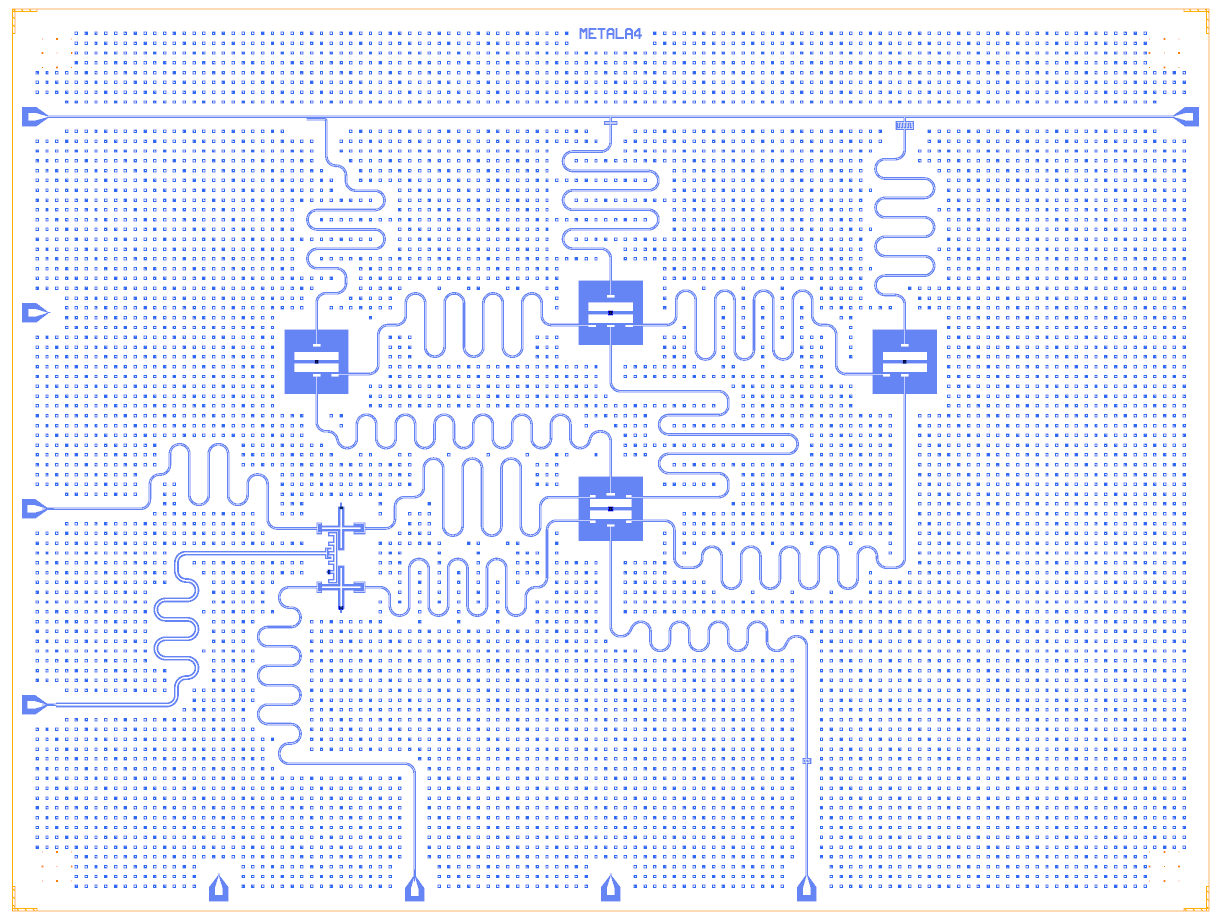

**On the chip so far:** 9 pads · 6 qubits · 5 other components · 19 routes · 2 declared couplings. **This step added** 1 component(s) `Tune_C_Q12` and 8 route(s) `Read_TuneC`, `Bus_01`, `Bus_02`, `Bus_03`, `Bus_04`, `Bus_05`, `Bus_Q3_Q4`, `Bus_Q4_Q5`.

WindowsPath('examples/designs/metal/a4_full_chip_s6_coupling.png')

In [10]:
with d.batch():
    tc = d.add("Tune_C_Q12", "metal:TunableCoupler01", at=P(-2810, -1500), rot=90, c_width=500, junction=SQUID,
               **SQ_PARAMS)
    d.route("Read_TuneC", tc.Control, l_tcr.tie, meander=5800, r=R, nodes=[(1070, 3048), (1070, 1500)])
    # the coupler island ends face the qubits' cross arms (no route carries this): estimated, assumed
    # coupler island end (20 µm) facing a cross arm (20 µm) over ≈ 90 µm across ≈ 37 µm (coplanar strips)
    C_TC = round(est.coplanar_coupling(90, 20, 20, 37, est.substrate_eps(get_pdk())), 2)
    d.couple("Cg_Q1_TC", "Q1", "Tune_C_Q12", C_fF=C_TC, note="TC island end ↔ Q1 cross arm (CPS estimate)")
    d.couple("Cg_Q2_TC", "Q2", "Tune_C_Q12", C_fF=C_TC, note="TC island end ↔ Q2 cross arm (CPS estimate)")
    # buses from Q_Main (total lengths as in Metal; the meander footprints are the qcc router's)
    d.route("Bus_01", qm.bus_01, q1.bus_01, meander=6000, r=R, nodes=[(4850, 3380), (4850, 2700)])
    d.route("Bus_02", qm.bus_02, q2.bus_02, meander=6400, r=R, nodes=[(3300, 3620), (3300, 3300)])
    d.route("Bus_03", qm.bus_03, q3.bus_03, meander=6800, r=R, nodes=[(5500, 4290), (2500, 4290)])
    d.route("Bus_04", qm.bus_04, q4.bus_04, meander=7200, r=R, nodes=[(6700, 3620), (6700, 4700), (5500, 4700)]).set(meander_segment=3)
    d.route("Bus_05", qm.bus_05, q5.bus_05, meander=7600, r=R, nodes=[(6150, 3380), (6150, 2900), (8500, 2900)])
    d.route("Bus_Q3_Q4", q3.bus_q3_q4, q4.bus_q3_q4, meander=6400, r=R, nodes=[(3130, 4875), (3130, 5375)])
    d.route("Bus_Q4_Q5", q4.bus_q4_q5, q5.bus_q4_q5, meander=6800, r=R, nodes=[(7800, 5375), (7800, 4875)])
print("coupler ports:", sorted(tc.ports), "| C(TC ↔ Q1/Q2) estimate:", C_TC, "fF")
layout_step(d, OUT / "a4_full_chip_s6_coupling.png", size=(1220, 920), width=480)

## Design 7 · Routing: the three flux lines

5/3 µm CPWs (`FL`) on Metal's `RoutePathfinder` paths, from the flux T-lines of `Q1`, `Q2` and the coupler to their
5/3 µm launchpads (`Flux_Line_Q1`, `Flux_Line_TuneC`, `Flux_Line_Q2`). They end on pads that moved to the edge in
Design 2, so each is longer by the pad move (4582, 3306 and 3954 µm before the move); the Q2 line's corners move by
up to 85 µm (Metal's 175 µm lead is too short for two 99 µm fillets in the qcc router).

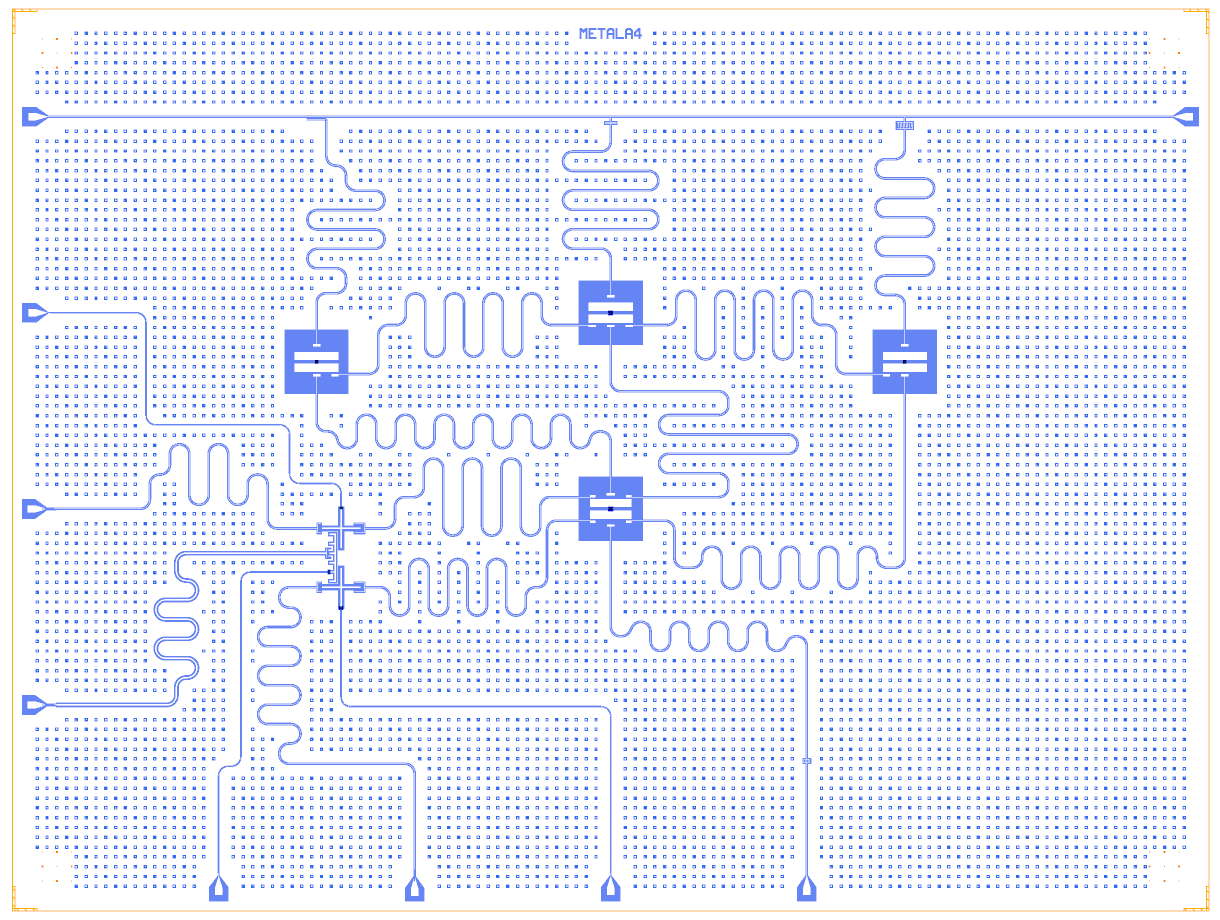

**On the chip so far:** 9 pads · 6 qubits · 5 other components · 22 routes · 2 declared couplings. **This step added** 3 route(s) `Flux_Line_Q1`, `Flux_Line_TuneC`, `Flux_Line_Q2`.

WindowsPath('examples/designs/metal/a4_full_chip_s7_flux_lines.png')

In [11]:
FL = dict(a=5, b=3)                              # flux lines 5/3 µm
with d.batch():
    # flux lines (Metal RoutePathfinder paths)
    d.route("Flux_Line_Q1", q1.flux_line, l_q1fl.tie, r=R, nodes=[(2750, 1483), (5500, 1483)], **FL)
    d.route("Flux_Line_TuneC", tc.Flux, l_tcfl.tie, r=R, nodes=[(1728, 2856), (1728, 875), (1500, 875)], **FL)
    d.route("Flux_Line_Q2", q2.flux_line, l_q2fl.tie, r=R,
            nodes=[(2750, 3760), (2225, 3760), (2225, 4358), (760, 4358), (760, 5500)], **FL)
layout_step(d, OUT / "a4_full_chip_s7_flux_lines.png", size=(1220, 920), width=480)

## Design 8 · The whole chip: target, sim groups, centring, save

**Target.** `Q_Main` is the only qubit with a stated value (Metal's Q3D + LOM result: f_q 4.96 GHz, α −351 MHz); its
junction was sized for it (Design 4), and `d.targets` attaches it to the design, so the LOM tables show it in brackets
and the feedback (Results 4) works towards it.

**Sim groups** say what a FEM job cuts out of the chip: `QMain` alone (the tutorial's own Q3D), `Q1_TC_Q2` (the two
crossmons with the coupler: it replaces the assumed coupler C) and `Q3_read` … `Q5_read` (each qubit with its readout
and tee, Q3D and eigenmode). The margins make each box cut every other line once (no meander lobes inside).

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre; pads given an `edge` slide back to
their 100 µm (`frame.pad_edge`) along it. Here the west and east pads span the die in x, so x is centred already. In y the content is
pinned at both ends: the four south pads sit at the bottom edge, and the north feedline ends on `Launch_NW` /
`Launch_NE`, on the west / east edges just below the top corners' 500 µm marker areas. Shifting it up by the
≈ 450 µm `center_in_die` asks for puts those two pads onto the marker areas (DRC `frame_keepout`; tried while
writing this notebook), and it does not even centre the box (the south pads slide back down). So this chip keeps the
source's vertical placement: centred in x, pinned by its pads in y (the source itself has its pads 0.5 mm from both
its bottom and top edges; only the bottom ones could move to the edge). The cell measures the offset and centres x
if it were needed.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the tees and the routes were added in another order here), so `git diff` stays
empty.

content box (-500, -500) – (11500, 7598) µm; centre − die centre (-0, -451) µm


**Same design as before:** `examples/designs/metal/a4_full_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a4_full_chip: 20 instances, 22 routes, live=False> → examples\designs\metal\a4_full_chip.json
route lengths (µm): {'ML_TL_01': 2515, 'ML_TL_02': 2720, 'ML_TL_03': 2810, 'ML_TL_04': 2605, 'Read_Q_Main_Cap_Launch': 1069, 'Read_Q_Main': 5600, 'Read_Q1': 6800, 'Read_Q2': 5400, 'Read_Q3': 5000, 'Read_Q4': 5800, 'Read_Q5': 5400, 'Read_TuneC': 5800, 'Bus_01': 6000, 'Bus_02': 6400, 'Bus_03': 6800, 'Bus_04': 7200, 'Bus_05': 7600, 'Bus_Q3_Q4': 6400, 'Bus_Q4_Q5': 6800, 'Flux_Line_Q1': 5322, 'Flux_Line_TuneC': 4046, 'Flux_Line_Q2': 4694}


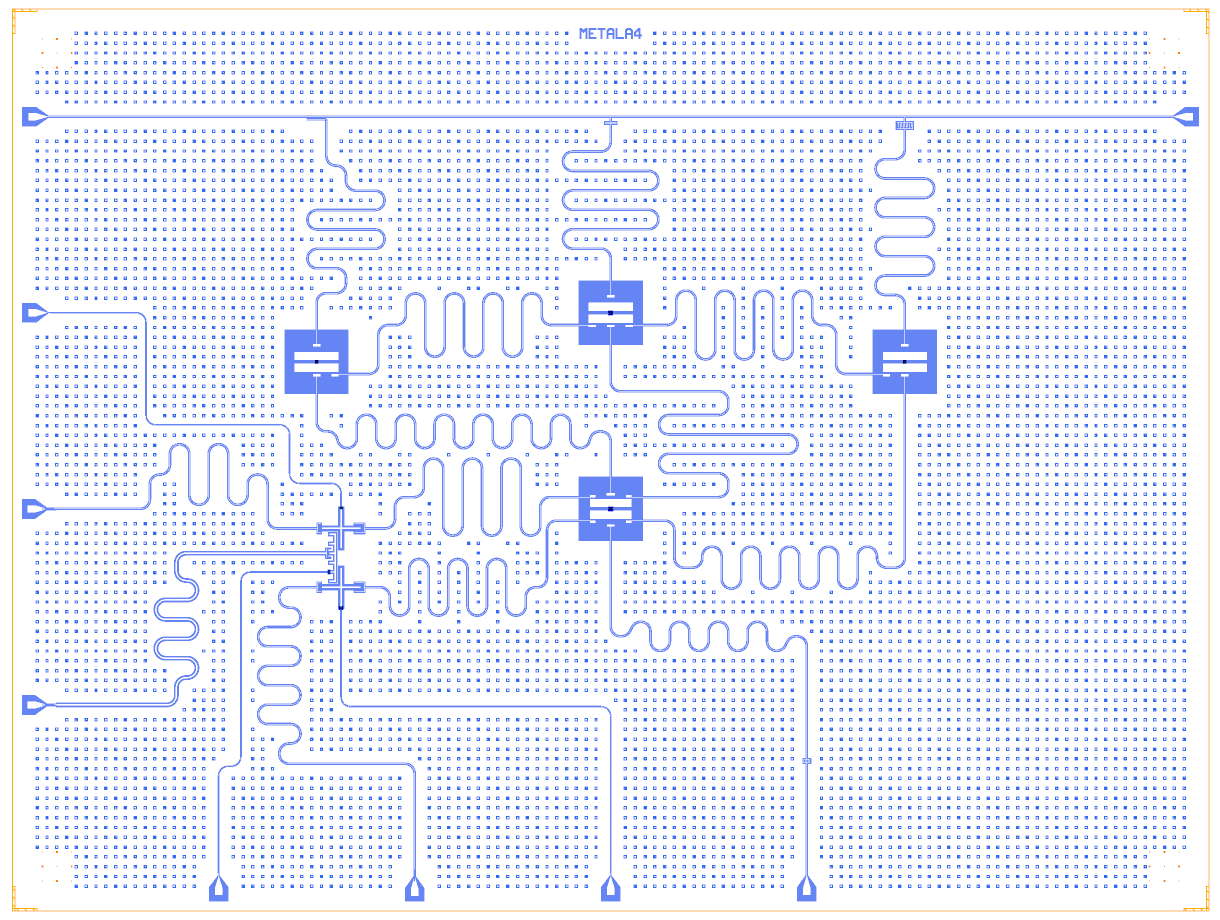

**On the chip so far:** 9 pads · 6 qubits · 5 other components · 22 routes · 2 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a4_full_chip_step_routes.png')

In [12]:
TARGETS = {"Q_Main": {"f_q_GHz": 4.96, "alpha_MHz": -351}}   # Metal's Q3D + LOM result (tutorial)
d.targets(**TARGETS)
# FEM boxes: margins chosen so that each box cuts every other line once (no meander lobes inside)
d.sim_group("QMain", ["Q_Main"], margin_um=150, analyses=["q3d_cmatrix"])
d.sim_group("Q1_TC_Q2", ["Q1", "Q2", "Tune_C_Q12"], margin_um=60, analyses=["q3d_cmatrix"])
for k, m in ((3, 80), (4, 100), (5, 150)):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"Read_Q{k}", f"Q{k}_Read_T"], margin_um=m, analyses=["q3d_cmatrix", "eigenmode_epr"])
box = content_box(d)
x0, y0, x1, y1 = d.design.chip.box
dx, dy = round((x0 + x1) / 2 - box.center().x, 1), round((y0 + y1) / 2 - box.center().y, 1)
print(f"content box ({box.left:.0f}, {box.bottom:.0f}) – ({box.right:.0f}, {box.top:.0f}) µm; "
      f"centre − die centre ({-dx:+.0f}, {-dy:+.0f}) µm")
if abs(dx) > 50:
    translate_design(d, dx, 0.0)                 # x only: y is pinned by the pads (see above)
rebuild(d)
DESIGN, same = save_design(d, OUT / "a4_full_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a4_full_chip_step_routes.png", size=(1220, 920), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; `dangling_port` warnings for the junction attachment points of the qubit and
coupler cells (`squid_a` / `squid_b`, the cell draws the junction itself) and the unused claws; two `overlap`
warnings, the coupler's bounding box overlapping those of `Q1` and `Q2` (in the source the coupler sits between the
two crosses with its island ends facing their arms; the metal does not touch). **PDK design warnings**, flagged and
not retuned:
- `pdk_rn` on `Q_Main` (R_n ≈ 98 kΩ: sized for the tutorial's 4.96 GHz on a small pocket);
- nothing else: the PDK SQUIDs of `Q1`, `Q2` and the coupler are judged on their parallel R_n (45 kΩ, in the window),
  and the 95 µm `claw_length` of `Q1` / `Q2` is well short of their 200 µm arms (no `pdk_claw`).

No `pad_edge` warnings: all nine pads are at 100 µm.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: `TransmonPocket6` → two floating pad nodes with the junction
between them, plus a node per connection pad; `TransmonCrossFL` → a grounded cross island with a SQUID, a node per
claw and the flux line as a control; `TunableCoupler01` → a grounded island with a SQUID, the `Control` claw as a node,
`Flux` as a control. Every bus between two pads is a λ/2 `TLres`; the readouts ending on a coupled launchpad, the
series capacitor or a `CapNInterdigitalTee` are λ/2, the shorted `CoupledLineTee` makes `Read_Q3` a λ/4 with a
hanger κ into the feedline. The two `d.couple` capacitances join the coupler island to the two cross islands.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q_Main.", "Tune_C_Q12."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Per qubit with its readout (the feedline groups include the whole north line, so the other tees' short stubs show
up as ≈ 100 GHz modes); then each bus with the two qubits it joins (static ZZ), and `Q1`–coupler–`Q2`. From the v1
run:

- `Q_Main` lands on the tutorial's target (in brackets): 4.98 GHz, α −376 MHz against 4.96 GHz, −351 MHz (its
  junction was sized for it on the pre-rebuild C_Σ; the pocket model is the analytic pad estimate, the Q3D job
  `QMain` gives the C-matrix).
- `Q1` and `Q2` (PDK SQUIDs at zero flux) sit at 5.79 GHz; they are identical, so their modes hybridise through the
  coupler and per-pair ZZ is not defined. The coupler SQUID sits at 8.3 GHz at zero flux, above the 4–8 GHz band
  (it is flux-tuned down in operation).
- `Q3`–`Q5` (PDK nominal junctions) sit at 7.1–7.2 GHz. The resonator lengths are the tutorial's rough choices: the
  λ/2 readouts land at 8.9–11.0 GHz, `Read_Q3` (λ/4 on the shorted tee) at 5.7 GHz, below its qubit. Static ZZ
  through the buses: −0.1 … −6 kHz to `Q_Main`, 47 / 75 kHz for `Q3`–`Q4` / `Q4`–`Q5`. Collisions and spreads are
  shown, not retuned (the values are the source's).
- `Q4`'s readout tee has `finger_length` 0 (Metal: "finger count sets the width of the gap capacitance"); the LOM
  treats it as a gap capacitor (a rough coplanar estimate). The FEM job `Q4_read` gives the real value.

In [ ]:
feed = ["Launch_NW", "Launch_NE", "ML_TL_01", "ML_TL_02", "ML_TL_03", "ML_TL_04"]
read = {
    "Q_Main+read": ["Q_Main", "Read_Q_Main", "Read_Q_Main_Cap", "Read_Q_Main_Cap_Launch", "Launch_QMain_Read"],
    "Q1+read": ["Q1", "Read_Q1", "Launch_Q1_Read"],
    "Q2+read": ["Q2", "Read_Q2", "Launch_Q2_Read"],
    "TC+read": ["Tune_C_Q12", "Read_TuneC", "Launch_TuneC_Read"],
    **{f"Q{k}+read": [f"Q{k}", f"Read_Q{k}", f"Q{k}_Read_T", "Q3_Read_T", "Q4_Read_T", "Q5_Read_T"] + feed
       for k in (3, 4, 5)},
}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, TARGETS)))
buses = {f"Q_Main+Bus_0{k}+Q{k}": ["Q_Main", f"Bus_0{k}", f"Q{k}"] for k in range(1, 6)}
buses |= {"Q3+Bus_Q3_Q4+Q4": ["Q3", "Bus_Q3_Q4", "Q4"], "Q4+Bus_Q4_Q5+Q5": ["Q4", "Bus_Q4_Q5", "Q5"],
          "Q1+TC+Q2": ["Q1", "Tune_C_Q12", "Q2"]}
coupled = simulate_groups(d, buses, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values; the red bar `Q_Main`'s target), (b) the dispersive shift |χ| of
each readout. From the v1 run the plot shows the collisions of LOM 1: the λ/2 readouts at 8.9–11.0 GHz far above
their qubits, `Read_Q3` (5.7 GHz) below `Q3`, and `Bus_05` within 0.3 GHz of `Q5`.

In [ ]:
plot_lom({**results, **coupled}, OUT / "a4_full_chip_lom.png", targets=TARGETS, title="a4: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here `Q_Main`'s junction, from the 14.6 nH junction sized for the tutorial's 4.96 GHz
(R_n ≈ 98 kΩ, outside the PDK window) to the PDK nominal 6.73 nH (R_n 45 kΩ, inside it) — rebuild, re-run the LOM of
`Q_Main` with its readout and compare. This is the choice the PDK rule leaves open: keep the source's frequency and
flag R_n, or keep R_n in the window and accept a higher f_q (still inside 4–8 GHz).

In [ ]:
d2 = design_copy(DESIGN)
d2["Q_Main"].set(junction=JUNCTION, junction_params={"lj_nH": JUNCTION["Lj_nH"]})   # 14.6 → 6.73 nH (PDK nominal)
group = {"Q_Main+read": read["Q_Main+read"]}
display(Markdown(params_delta_md({"Q_Main+read": results["Q_Main+read"]}, simulate_groups(d2, group))))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D **C-matrix** jobs for `Q_Main` alone (the tutorial's own Q3D: readout pad 42.1 fF, pad_top 97.5 fF,
pad_top–pad_bot −31.2 fF), for `Q1`–coupler–`Q2` (this replaces the assumed coupler C) and for `Q3`–`Q5` with their
readouts and tees; **eigenmode / EPR** jobs for those three readouts (the lines leaving the box end in 50 Ω, so the
mode Q gives κ).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, ["Q3_read", "Q4_read", "Q5_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `QMain` (`Q_Main`'s two pads and six connection pads: the tutorial compares
its readout pad 42.1 fF, pad_top 97.5 fF and pad_top–pad_bot −31.2 fF), `Q1_TC_Q2` (the two cross islands, the coupler
island and their claws: this replaces the assumed 6 fF couplings) and `Q3_read` … `Q5_read` (each qubit with its
readout stub and tee). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q3_read` … `Q5_read` boxes in HFSS eigenmode: each junction is a lumped L_J ‖ C_J sheet, the feedline and every
other line the box cuts end in 50 Ω, so each mode's Q gives κ (through the tee into the feedline). pyEPR (run inside
qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed
frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it. Here for `Q3_read`: `Read_Q3` is a λ/4 hanger on the shorted coupled-line tee, so the feedline's
S21 has the notch the fit is made for (f0 and κ_ext). In the LOM its resonator is labelled by the tee, `Q3_Read_T`.

In [ ]:
f_r3 = results["Q3+read"].params.get("Q3_Read_T.f_GHz")       # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q3_read", jobs_eig["Q3_read"][0], keep_eig["Q3_read"], f_guess=f_r3)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q3_read"]:
    display(Markdown(driven_md(keep_drv["Q3_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
RO = {3: "Q3_Read_T", 4: "Read_Q4", 5: "Read_Q5"}  # each readout's LOM label (Read_Q3 is labelled by its tee)
lom_f = {}
for k, r in RO.items():
    lom_f[f"Q{k}"] = results[f"Q{k}+read"].params.get(f"Q{k}.f_q_GHz")
    lom_f[r] = results[f"Q{k}+read"].params.get(f"{r}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "a4_full_chip_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds the `Read_Q3` notch.

In [ ]:
fem_values = {}
for k, r in RO.items():
    keep = keep_eig.get(f"Q{k}_read")
    if keep:
        fem_values[f"Q{k}"] = epr_values(keep, {f"Q{k}": r}, {r: lom_f[r]})
if keep_drv["Q3_read"]:
    fem_values.setdefault("Q3", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q3_read"], "Q3_Read_T", f_r3).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of Q3–Q5 and their "
          "readouts from pyEPR, and the S21 notch of Read_Q3.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again — `Q_Main` with its readout on the `QMain` job, `Q3`–`Q5` on their `Q<k>_read` jobs. **FEM directly:** the
eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
for q, g, job, r in [("Q_Main", "Q_Main+read", "QMain", "Read_Q_Main")] + [(f"Q{k}", f"Q{k}+read", f"Q{k}_read", RO[k])
                                                                         for k in RO]:
    lom_p = results[g].params
    keys = [f"{q}.f_q_GHz", f"{q}.alpha_MHz", f"{r}.f_GHz", f"{r}.chi_MHz", f"{r}.kappa_MHz"]
    if keep_q3d.get(job):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[job]), max_modes=2).params
        rows += [(key, lom_p.get(key), on_fem.get(key), f"LOM on the {job} C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(q, {}):
            rows.append((key, lom_p.get(key), fem_values[q][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrices and next to the eigenmodes, with the difference in %.")

## Results 4 · Feedback: one step towards `Q_Main`'s target

The design has one target of its own, `Q_Main` at f_q 4.96 GHz and α −351 MHz (Design 8, saved in the JSON).
`target_copy(DESIGN, {})` writes the design with it (nothing added) to `build/a4_full_chip_target.json`, and the
feedback works on that copy. From the v1 run `Q_Main` sits at 4.977 GHz (inside the ± 20 MHz f_q tolerance) and α at
−375.5 MHz, so the step is mostly on α: the pocket's `pad_width` (the island knob; a smaller C_Σ gives a larger |α|,
so here a wider pad).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — the chip has seven, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per
quantity (the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the
target inside its tolerance; the proposal is written as revision 1, built and netlist-checked.

**No PDK window for `Q_Main`.** Its junction is already outside the 40–50 kΩ window (R_n ≈ 98 kΩ, Design 4):
`pdk_lj_bounds` would pull its L_J into it, i.e. `Q_Main` to ≈ 7 GHz (LOM 3 shows the PDK nominal), away from the
target. So the feedback runs without those bounds; the DRC keeps flagging `pdk_rn` (the value is the source's). A
revision that changes `pad_width` moves `Q_Main`'s corner bus pins (`loc_W` ±1): read its DRC line.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own target (Q_Main), nothing added
BOUNDS = None                                    # no PDK R_n window for Q_Main: its target needs L_J outside it
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until the
target is inside its tolerance or `MAX_ITER` revisions are made (`build/a4_full_chip/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's `QMain` Q3D job is exported and solved first
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the target and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's QMain Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = export_sims(rev, ["QMain"], root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a4_full_chip_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.4 notebook exports its chip to GDS with Metal's `QGDSRenderer`, whose default cheeses the whole ground (`cheese.view_in_file = {main: {1: True}}`: `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm, `edge_nocheese` 200 µm) and sets `no_cheese.buffer = 50um`. So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (Design 1: `metal_cheese_rule(buffer=50)` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's last screenshot: same components and pins, different meander footprints);
`Q_Main` with its six pads; its trilayer junction; `Q1`, `Q2` and the tunable coupler between them (flux lines from
the left and below); the `Q4` interdigital tee on the north feedline; the **fab mask** round `Q_Main` (1/0 etch with
the original's Metal cheese, 25 µm holes every 100 µm, the 3/0 keep-out, the junction layers); and the die frame's
south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are read from the design.

In [ ]:
QX, QY = d.data["instances"]["Q_Main"]["place"]["at"]
CX, CY = d.data["instances"]["Tune_C_Q12"]["place"]["at"]
TX, TY = d.data["instances"]["Q4_Read_T"]["place"]["at"]
show_snapshot(d, OUT / "a4_full_chip.png", size=(1650, 1200))
show_snapshot(d, OUT / "a4_full_chip_qmain.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a4_full_chip_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a4_full_chip_coupler.png", box=(CX + 60 - 400, CY - 650, CX + 60 + 400, CY + 650),
              size=(800, 1300), width=360)
show_snapshot(d, OUT / "a4_full_chip_tee.png", box=(TX - 200, TY - 250, TX + 200, TY + 100), size=(800, 700), width=360)
snap_file(Path("build") / "a4_full_chip_fab.oas", OUT / "a4_full_chip_cheese.png",
          box=(QX - 900, QY - 900, QX + 900, QY + 900), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a4_full_chip_frame.png", box=(-600, -600, 300, 300), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the route end pins and total lengths (buses 6.0–7.6 mm, readouts 5.0–6.8 mm), the flux-line paths, the sim groups; the original's Metal GDS cheese (25 µm / 100 µm, 50 µm buffer) drawn by the build and kept in the mask |
| PDK changes | QCT frame on the grown 12.2 × 9.2 mm box; sapphire stack; nine launchpads 100 µm from their edges (were 840–850 µm); trilayer junctions (Q_Main sized for 4.96 GHz, Q3–Q5 nominal, Q1 / Q2 / coupler PDK SQUIDs); content centred in x; in y pinned by the south pads and the NW / NE pads below the marker areas (offset printed in Design 8, not shifted) |
| differs | the meander footprints (qcc router); the qubit frequencies move with the PDK junctions, so several buses / readouts collide with qubits (LOM 1, from the v1 run); the flux lines are longer by the pad shift |
| PDK design warnings | `pdk_rn` Q_Main (≈ 98 kΩ: sized for the tutorial's 4.96 GHz; LOM 3 shows the PDK nominal instead) |
| layout | built in segments (die, pads, the north feedline and the series capacitor, qubits, readouts, the coupler with the buses, flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | towards `Q_Main`'s own target on a copy: `loop.analyse` → `loop.feedback` → revisions until on target (no PDK R_n bounds: the target needs L_J outside the window; LOM, FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |